# 4. Visualisasi Map (Folium)

## Visualisasi Prediksi Model Terbaik (KNN)

Pada tahap ini, model KNN dengan $k=5$ digunakan untuk memprediksi kelas tutupan lahan pada level poligon. Tujuannya adalah memvisualisasikan hasil prediksi dalam bentuk peta interaktif agar pola spasial dapat dianalisis secara intuitif. Penggunaan peta interaktif memungkinkan pengguna melihat kesesuaian antara label aktual dan prediksi pada wilayah tertentu, serta memudahkan identifikasi area yang mengalami kesalahan klasifikasi.

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import folium
from shapely.geometry import Point, MultiPoint
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
df = pd.read_csv('../hasil_s2_piksel/dataset.csv')

fitur = ['B02', 'B03', 'B04', 'B08', 'B11', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']
df = df.dropna(subset=fitur + ['label_teks']).copy()

# Ringkas fitur per poligon agar representasi spasial lebih stabil
poligon_summary = (
    df.groupby('poligon_id')
      .agg(
          label_aktual=('label_teks', 'first'),
          label=('label', 'first'),
          lon=('lon', 'mean'),
          lat=('lat', 'mean'),
          B02=('B02', 'mean'),
          B03=('B03', 'mean'),
          B04=('B04', 'mean'),
          B08=('B08', 'mean'),
          B11=('B11', 'mean'),
          NDVI=('NDVI', 'mean'),
          NDWI=('NDWI', 'mean'),
          MNDWI=('MNDWI', 'mean'),
          NDBI=('NDBI', 'mean'),
      )
      .reset_index()
)

# Split data
X = poligon_summary[fitur]
y = poligon_summary['label_aktual']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred = knn_model.predict(X_test_scaled)

print('Akurasi model KNN:', round(accuracy_score(y_test, y_pred) * 100, 2), '%')
print(classification_report(y_test, y_pred))

Akurasi model KNN: 67.24 %
              precision    recall  f1-score   support

    Bangunan       0.62      0.80      0.70        10
       Danau       1.00      0.50      0.67        10
       Hutan       0.57      0.50      0.53         8
        Laut       0.83      1.00      0.91        10
    Mangrove       0.67      0.80      0.73        10
       Sawah       0.44      0.40      0.42        10

    accuracy                           0.67        58
   macro avg       0.69      0.67      0.66        58
weighted avg       0.69      0.67      0.66        58



In [2]:
# Evaluasi model per kelas
label_order = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=label_order)
cm_df = pd.DataFrame(cm, index=label_order, columns=label_order)
cm_df

,Bangunan,Danau,Hutan,Laut,Mangrove,Sawah
Bangunan,8,0,0,0,0,2
Danau,1,5,1,2,0,1
Hutan,3,0,4,0,0,1
Laut,0,0,0,10,0,0
Mangrove,0,0,1,0,8,1
Sawah,1,0,1,0,4,4


In [3]:
# Tambahkan prediksi ke dataframe poligon
poligon_pred = poligon_summary.loc[X_test.index].copy()
poligon_pred['prediksi'] = y_pred
poligon_pred['label_aktual'] = y_test.to_numpy()
poligon_pred.head()

,poligon_id,label_aktual,label,lon,lat,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI,prediksi
261,Sawah_0024,Sawah,1,111.770664,-7.146760,372.500000,682.386364,434.215909,3250.772727,1459.340909,0.764288,-0.652816,-0.363657,-0.379942,Mangrove
223,Mangrove_0036,Mangrove,6,112.843568,-7.280499,570.861494,898.195794,706.015954,2665.414793,1231.343727,0.523330,-0.441935,-0.106763,-0.375501,Mangrove
39,Bangunan_0039,Bangunan,2,113.213721,-8.144034,737.464000,936.432500,890.698000,2512.633500,1911.209000,0.465695,-0.440069,-0.327250,-0.142179,Sawah
38,Bangunan_0038,Bangunan,2,113.224410,-8.113379,823.667000,1017.756500,1049.609000,2224.299000,2005.819000,0.348084,-0.354472,-0.277708,-0.086074,Sawah
22,Bangunan_0022,Bangunan,2,112.778520,-7.235337,1473.591500,1680.417500,1870.521000,2349.095500,3023.266000,0.122051,-0.176182,-0.302828,0.130738,Bangunan


In [4]:
# Buat geodataframe untuk visualisasi peta interaktif
geometry = [Point(xy) for xy in zip(poligon_pred['lon'], poligon_pred['lat'])]
gdf = gpd.GeoDataFrame(poligon_pred, geometry=geometry, crs='EPSG:4326')

# Definisikan warna per kelas
class_colors = {
    'Sawah': '#2ca02c',
    'Bangunan': '#d62728',
    'Hutan': '#1f77b4',
    'Danau': '#17becf',
    'Laut': '#6a5acd',
    'Mangrove': '#8c564b',
}

m = folium.Map(location=[-7.5, 112.5], zoom_start=6, tiles='OpenStreetMap')

for _, row in gdf.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=5,
        color=class_colors.get(row['prediksi'], '#808080'),
        fill=True,
        fill_opacity=0.8,
        popup=(
            f"Aktual: {row['label_aktual']}<br>"
            f"Prediksi: {row['prediksi']}"
        ),
    ).add_to(m)

m

## Penjelasan Visualisasi KNN

Kode berikut bertujuan untuk menampilkan hasil klasifikasi pada level poligon dalam bentuk peta interaktif. Proses dimulai dengan menentukan fitur spektral yang digunakan dalam model, yaitu kanal reflectance Sentinel-2 (`B02`, `B03`, `B04`, `B08`, `B11`) serta indeks vegetasi dan hidrologi, yaitu NDVI, NDWI, MNDWI, dan NDBI. Data yang tidak lengkap pada fitur-fitur tersebut dibuang agar model tidak menerima nilai yang tidak valid.

Setelah fitur dan label ditentukan, data dibagi menjadi sampel yang seimbang per kelas dengan jumlah maksimum 600 piksel per kelas. Langkah ini penting untuk mengurangi bias pada kelas yang memiliki jumlah observasi lebih kecil dibanding kelas lain. Selanjutnya, fitur ditransformasikan menggunakan `StandardScaler`, karena algoritma KNN sangat sensitif terhadap skala variabel. Dengan penskalaan ini, semua fitur berada pada skala yang relatif seragam, sehingga jarak antar titik pada ruang fitur menjadi lebih representatif.

Pada tahap pemodelan, model KNN dibangun dengan parameter `n_neighbors=5`. Nilai ini dipilih agar setiap prediksi mempertimbangkan lima tetangga terdekat, sehingga klasifikasi tidak terlalu sensitif terhadap noise tunggal tetapi tetap cukup responsif terhadap pola lokal spektral. Setelah model dilatih, dilakukan agregasi fitur per poligon dengan cara menghitung rata-rata nilai piksel tiap variabel pada setiap poligon. Langkah ini menghasilkan representasi satu baris data per unit spasial, sehingga prediksi dapat dilakukan pada level poligon sebagai satu objek geometri.


Hasil agregasi kemudian diprediksi dengan model KNN yang sama. Prediksi label pada setiap poligon kemudian digabungkan dengan geometri `poligon_id` dan `geometry` untuk membentuk objek `GeoDataFrame`. Data ini selanjutnya ditampilkan dalam peta Folium. Pada peta, setiap poligon diberi warna sesuai kelas prediksi, sehingga distribusi spasial tutupan lahan dapat dilihat secara langsung.

Fungsi `folium.CircleMarker` digunakan untuk menempatkan titik pusat poligon pada peta dengan warna tertentu. Jika prediksi sesuai dengan label aktual, poligon ditampilkan dengan warna kelasnya. Namun, jika terdapat kesalahan prediksi, maka poligon diberi garis merah tebal sebagai penanda. Selain itu, simbol tanda seru merah ditambahkan pada lokasi centroid poligon tersebut untuk memperjelas bahwa terjadi ketidakcocokan antara label aktual dan prediksi.

Dengan demikian, visualisasi ini tidak hanya menampilkan hasil klasifikasi, tetapi juga membantu mengevaluasi kualitas model secara spasial. Analisis visual seperti ini sangat berguna untuk mengidentifikasi area yang secara geometris atau spektral sulit dibedakan, misalnya antara sawah dan hutan, atau antara pembangunan dan lahan terbuka. Dalam konteks pemodelan LULC, hal ini menjadi penting karena kesalahan klasifikasi sering terjadi pada wilayah transisi atau pada objek yang memiliki karakteristik spektral serupa.

## Evaluasi Model dan Hasil Klasifikasi

Pada tahap evaluasi, hasil prediksi model dibandingkan dengan label aktual pada data uji. Pengukuran yang digunakan meliputi akurasi keseluruhan, presisi, recall, dan F1-score. Selain itu, confusion matrix digunakan untuk melihat kelas yang paling sering tertukar, misalnya antara sawah dan bangunan, atau antara hutan dan mangrove pada wilayah transisi yang memiliki karakter spektral serupa.

In [5]:
# Ringkasan performa per kelas
report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
report_df

,precision,recall,f1-score,support
Bangunan,0.615385,0.800000,0.695652,10.000000
Danau,1.000000,0.500000,0.666667,10.000000
Hutan,0.571429,0.500000,0.533333,8.000000
Laut,0.833333,1.000000,0.909091,10.000000
Mangrove,0.666667,0.800000,0.727273,10.000000
Sawah,0.444444,0.400000,0.421053,10.000000
accuracy,0.672414,0.672414,0.672414,0.672414
macro avg,0.688543,0.666667,0.658845,58.000000
weighted avg,0.692581,0.672414,0.663173,58.000000


C:\Users\NEC VH-3\AppData\Local\Temp\ipykernel_16272\878471403.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='prediksi', data=poligon_pred, order=poligon_pred['prediksi'].value_counts().index, palette='viridis')


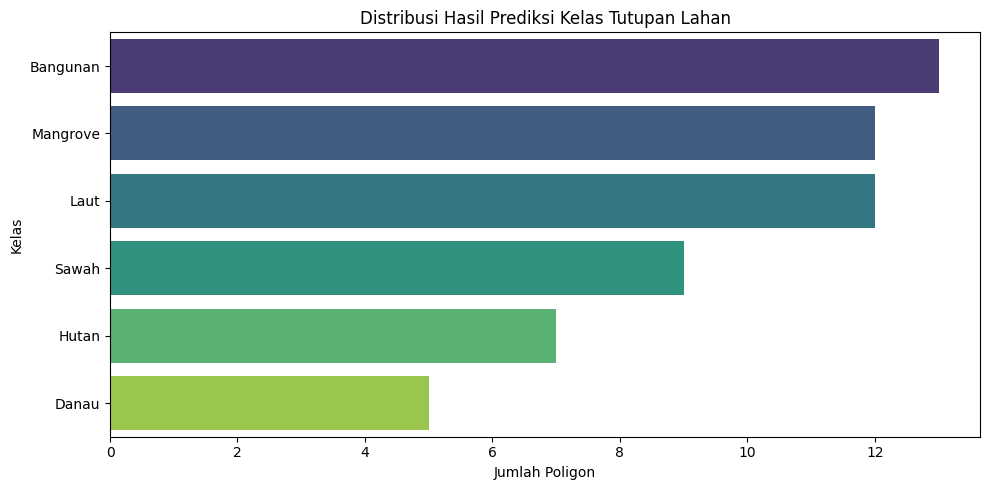

In [6]:
# Visualisasi distribusi hasil prediksi
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.countplot(y='prediksi', data=poligon_pred, order=poligon_pred['prediksi'].value_counts().index, palette='viridis')
plt.title('Distribusi Hasil Prediksi Kelas Tutupan Lahan')
plt.xlabel('Jumlah Poligon')
plt.ylabel('Kelas')
plt.tight_layout()
plt.show()

In [7]:
# Perbandingan aktual vs prediksi
comparison = (
    pd.crosstab(poligon_pred['label_aktual'], poligon_pred['prediksi'])
      .rename_axis(index='Label Aktual', columns='Label Prediksi')
)
comparison

Label Prediksi,Bangunan,Danau,Hutan,Laut,Mangrove,Sawah
Label Aktual,,,,,,
Bangunan,8,0,0,0,0,2
Danau,1,5,1,2,0,1
Hutan,3,0,4,0,0,1
Laut,0,0,0,10,0,0
Mangrove,0,0,1,0,8,1
Sawah,1,0,1,0,4,4


## Penjelasan Kode Visualisasi Peta Wilayah Utuh

Kode berikut digunakan untuk memetakan prediksi kelas tutupan lahan ke dalam peta interaktif yang menampilkan keseluruhan wilayah studi. Proses ini dimulai dengan membaca raster multi-band (`.tif`) yang berisi citra Sentinel-2 hasil komposit, kemudian menghitung indeks spektral seperti NDVI, NDWI, MNDWI, dan NDBI. Indeks-indeks ini digunakan untuk memperkuat karakteristik setiap kelas lahan, seperti vegetasi, air, dan kawasan terbangun.

Selanjutnya, prediksi kelas dilakukan secara per-piksel dengan memanfaatkan model KNN yang telah dilatih sebelumnya. Karena data raster berukuran besar, prediksi dilakukan dalam potongan (chunk) agar proses tetap efisien dan tidak membebani memori. Hasil prediksi kemudian disimpan dalam matriks dua dimensi yang merepresentasikan peta kelas untuk seluruh wilayah.

Pada tahap lanjutan, dilakukan segmentasi morfologis untuk memisahkan daratan dan laut secara spasial. Teknik seperti `binary_closing`, `binary_fill_holes`, dan `binary_dilation` digunakan untuk membersihkan noise, menutup celah kecil, dan menyatukan area lahan yang terputus-putus. Dengan cara ini, wilayah daratan yang benar dapat dibedakan dari kawasan air murni serta objek yang bukan bagian dari daratan utama.

Setelah mask daratan terbentuk, dilakukan koreksi kelas untuk mengurangi kesalahan prediksi yang sering terjadi pada wilayah transisi. Misalnya, area yang terdeteksi sebagai laut tetapi berada di daratan dan memiliki nilai NDVI yang tinggi akan dikoreksi menjadi hutan atau sawah. Area air di dalam daratan seperti danau juga dipisahkan berdasarkan nilai MNDWI dan intensitas band NIR. Langkah ini penting karena kelas tutupan lahan tidak selalu dapat dipisahkan hanya dari satu variabel saja; perlu ada penyesuaian berbasis karakteristik biofisik spasial.

Terakhir, hasil prediksi berupa label kelas dibentuk menjadi layer overlay pada peta Folium. Setiap kelas diberikan warna tertentu agar perbedaan wilayah mudah dilihat secara visual. Teknik `ImageOverlay` digunakan untuk menempatkan peta kelas pada background citra satelit Google, sehingga pengguna dapat melihat distribusi spasial kelas tutupan lahan secara interaktif di peta.


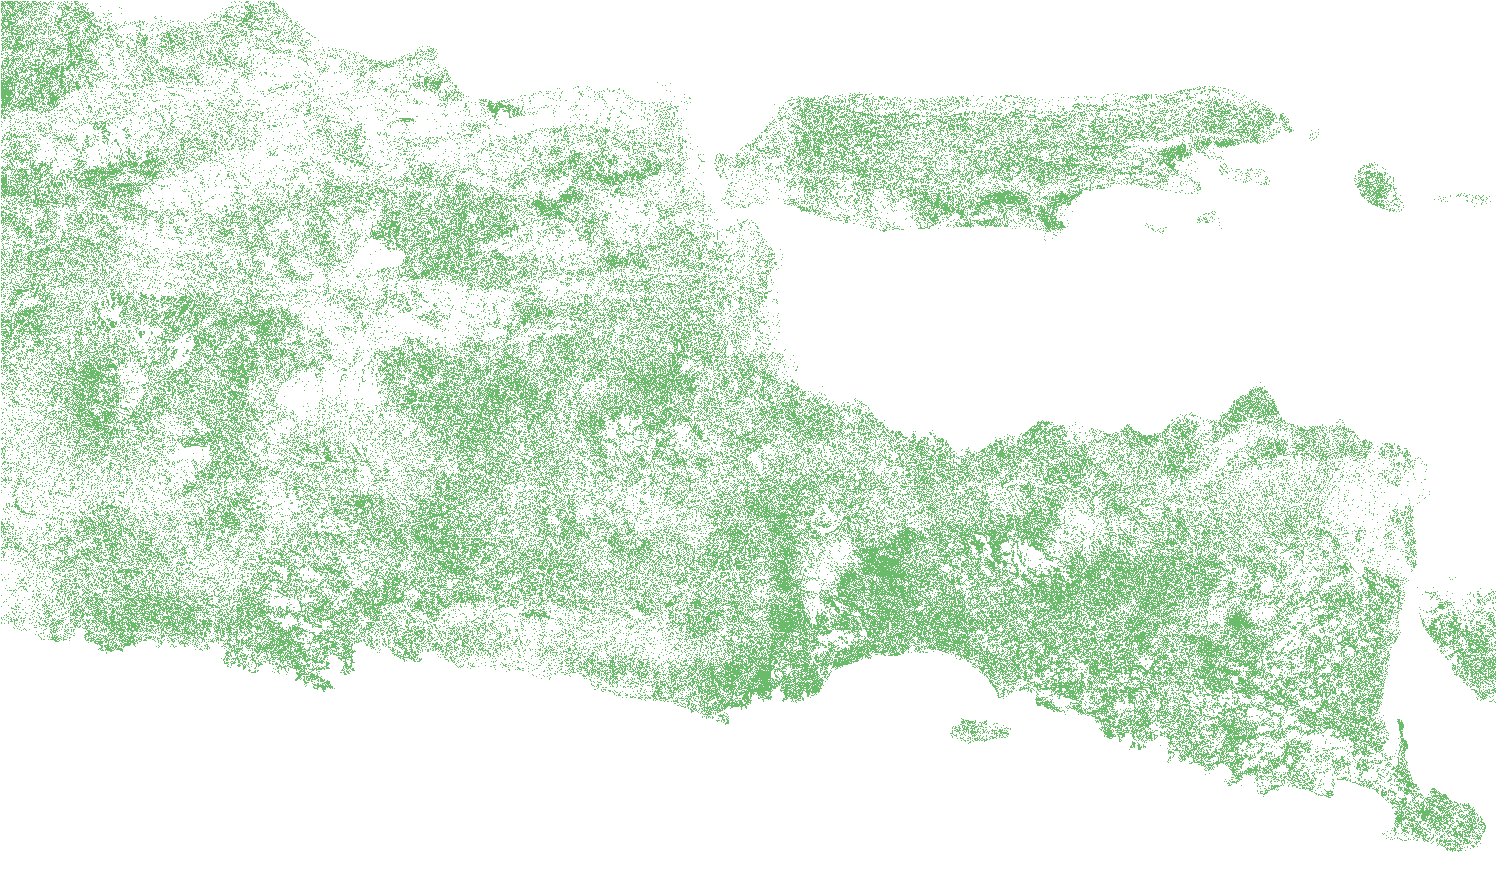
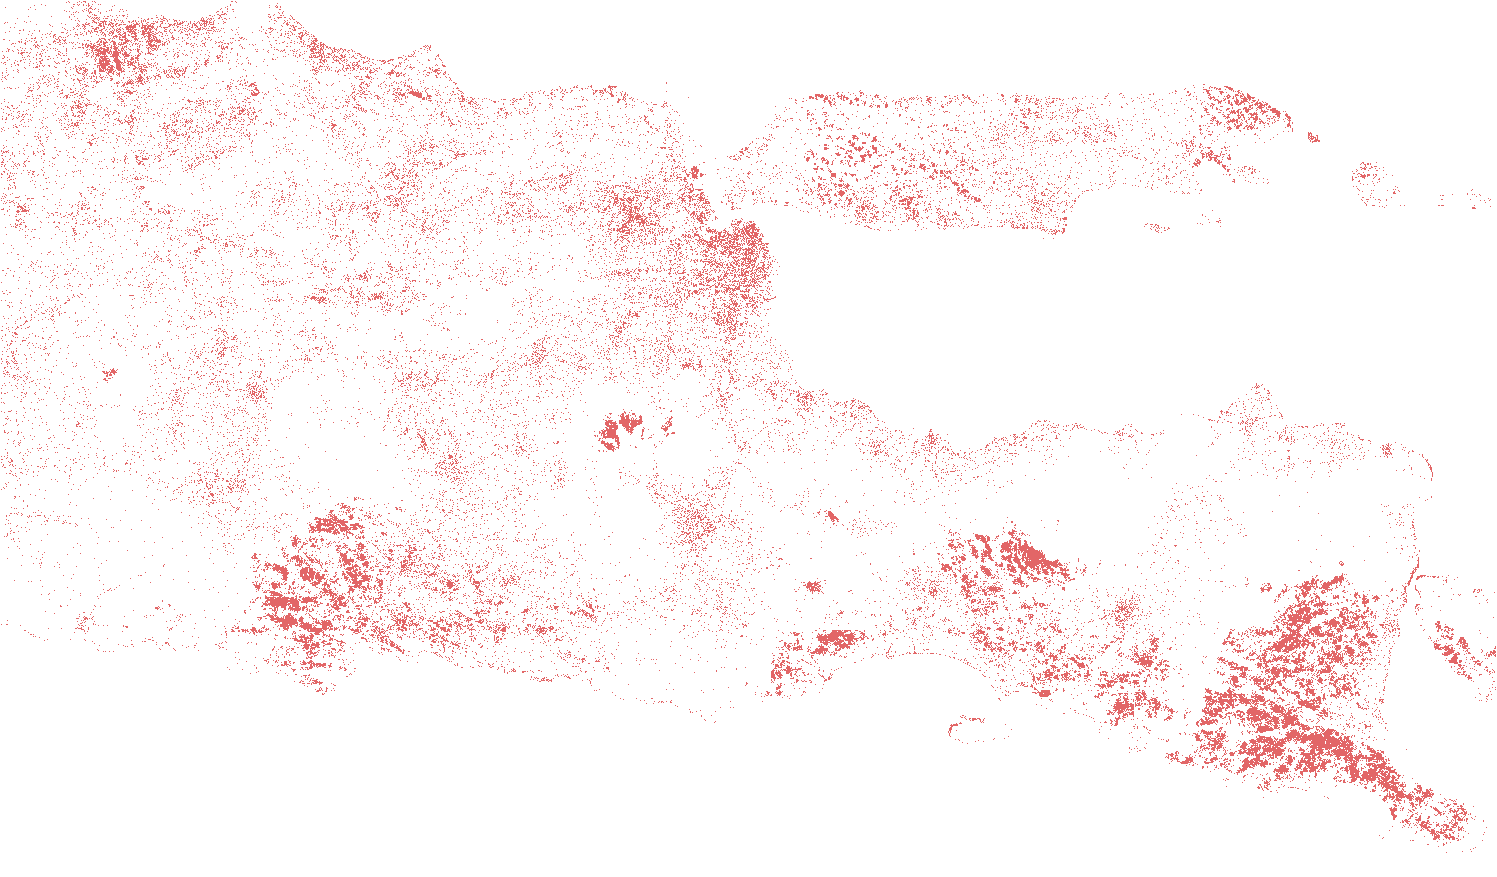
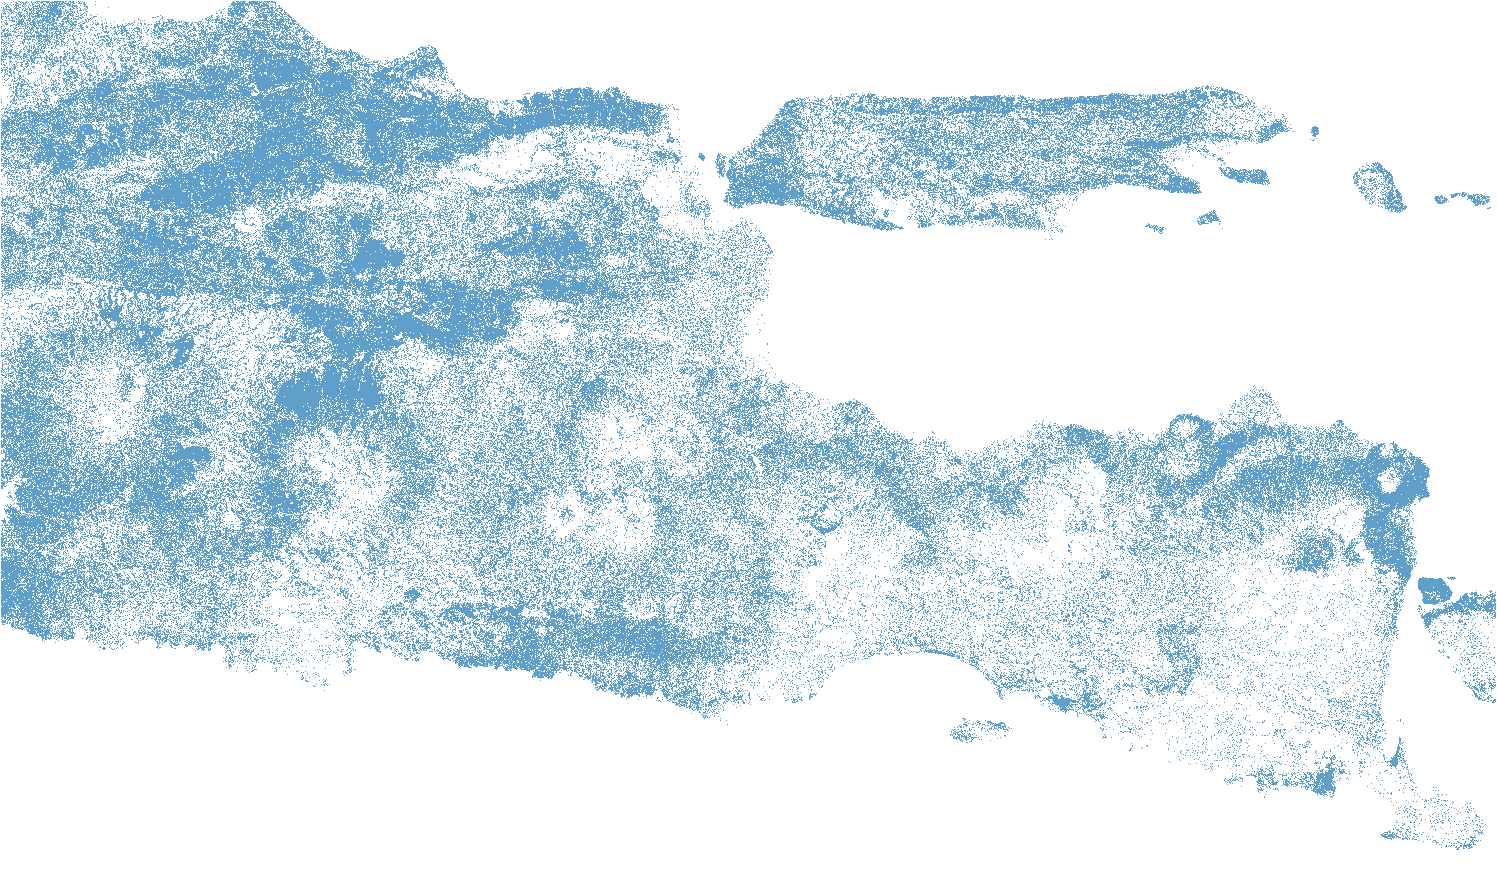
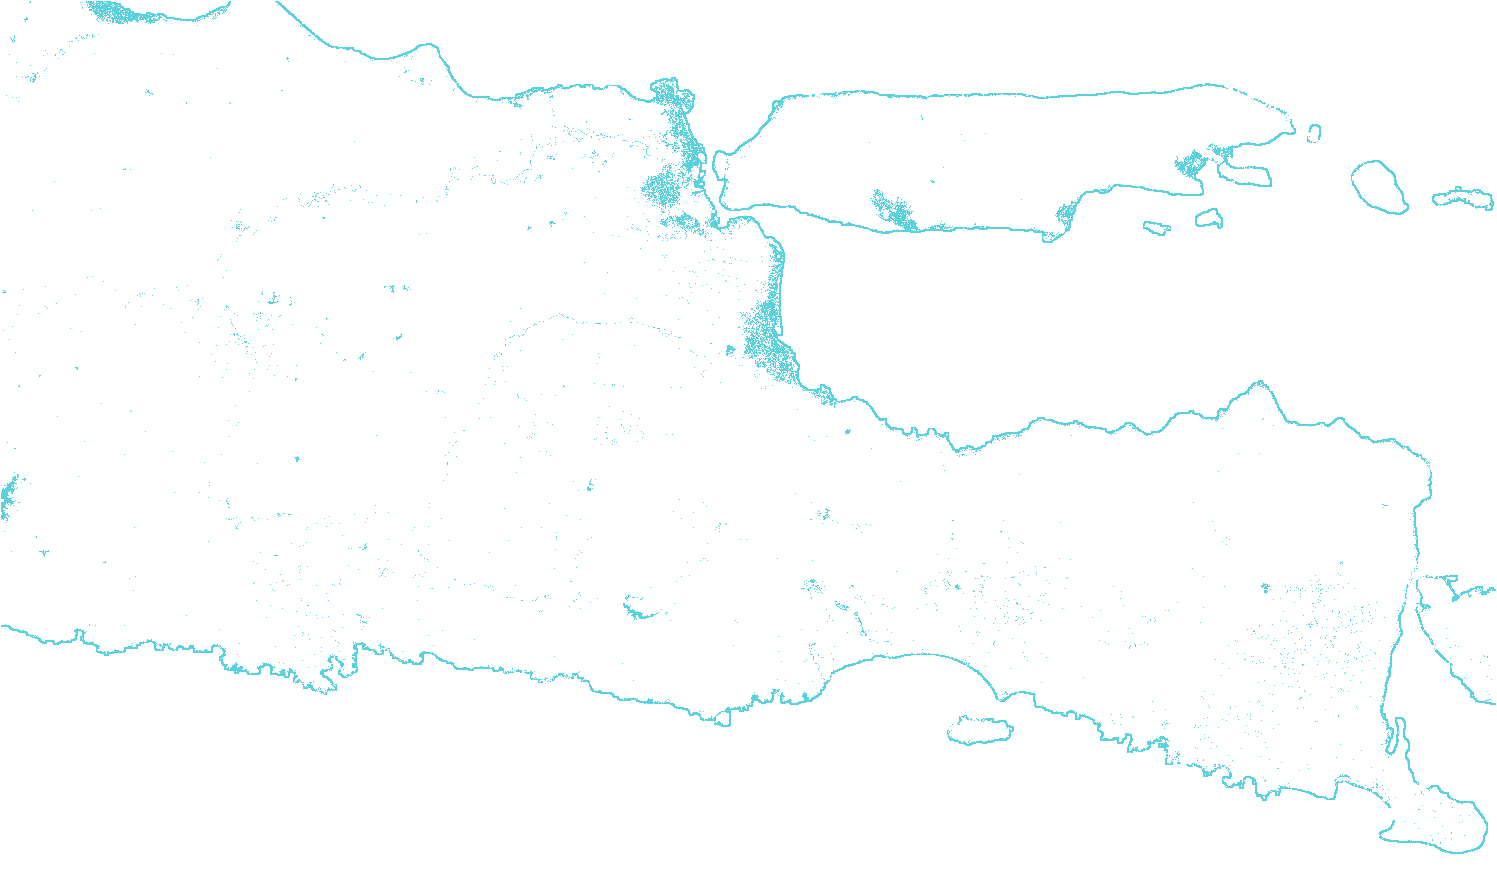
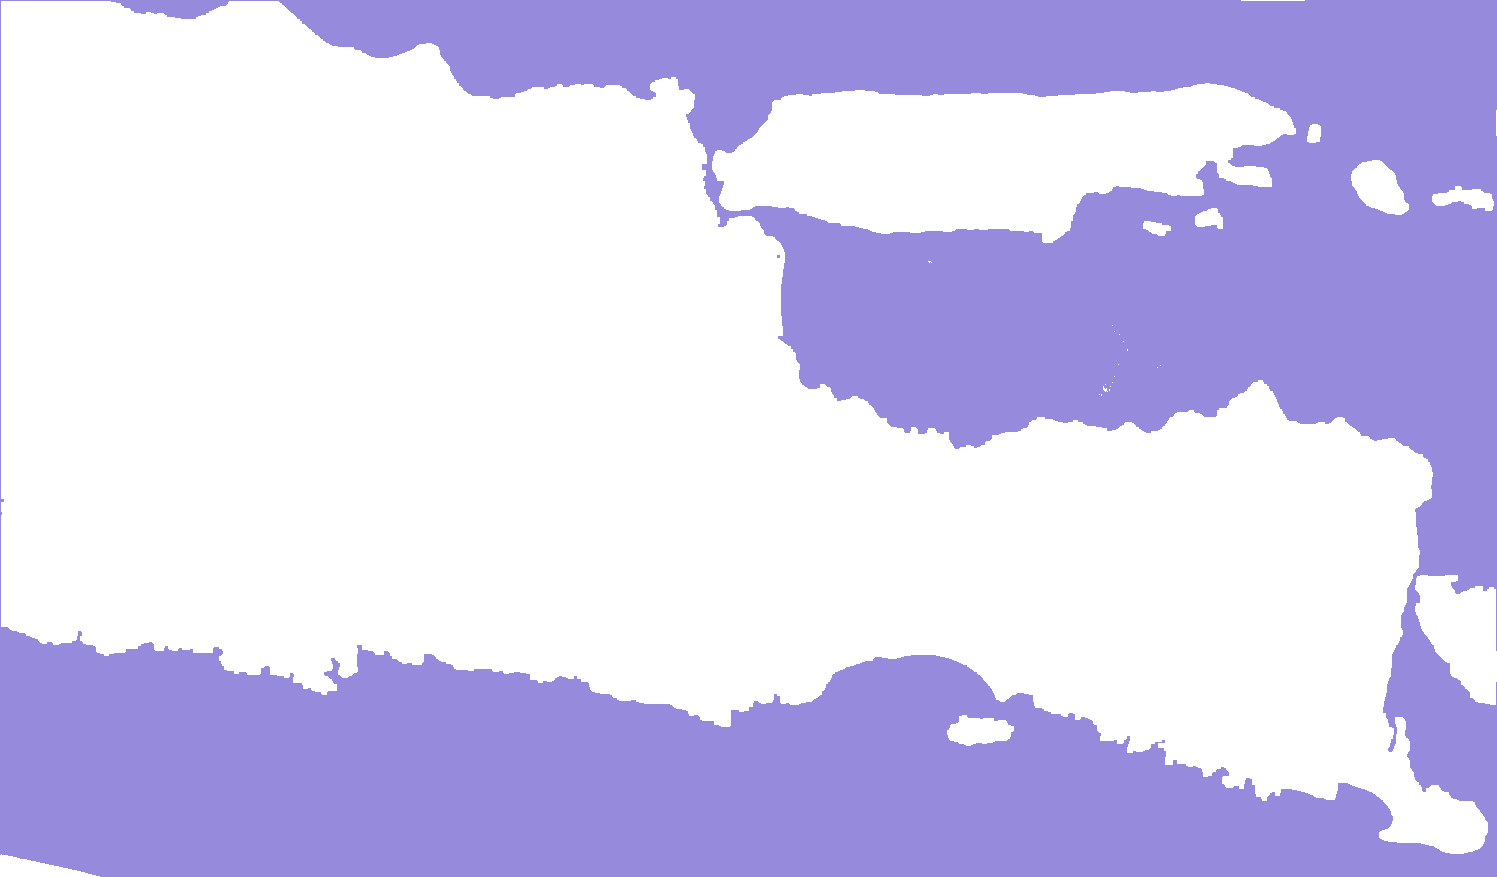
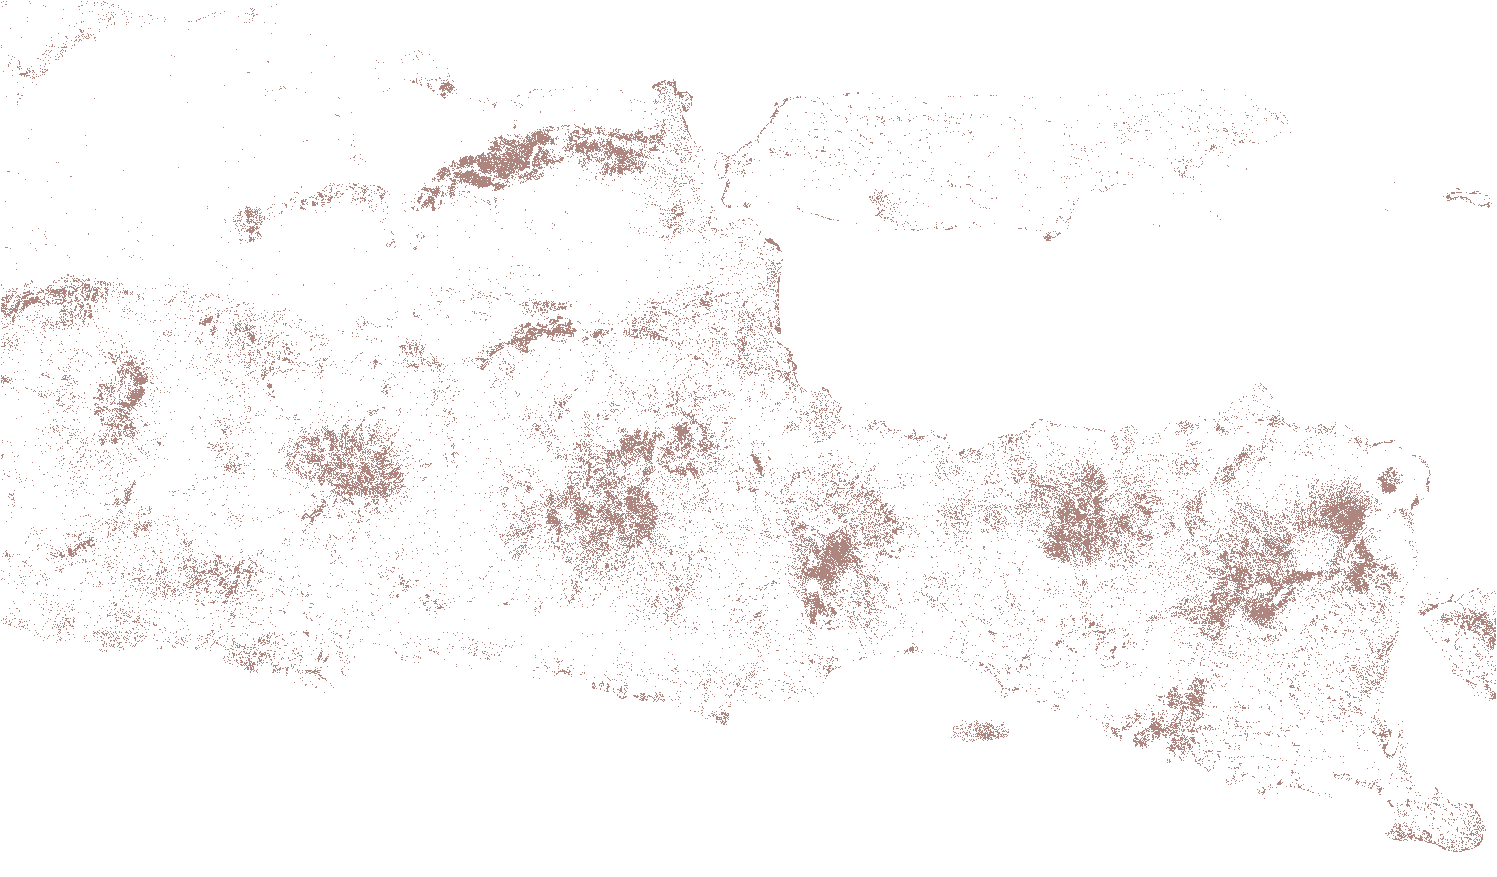

In [8]:
import os
import warnings
import rasterio
import numpy as np
import folium
from scipy.ndimage import label, binary_closing, binary_fill_holes, binary_dilation

warnings.filterwarnings('ignore')

# Fungsi pembantu: konversi kode warna hex (#RRGGBB) ke (R, G, B)
def hex_to_rgb(hex_code):
    hex_code = hex_code.lstrip('#')
    return tuple(int(hex_code[i:i+2], 16) for i in (0, 2, 4))

# Tentukan path raster wilayah utuh
FILE_RASTER = '../hasil_s2_piksel/jatim_250m.tif'
if not os.path.exists(FILE_RASTER):
    for p in ['jatim_250m.tif', '../Data/UTS/jatim_250m.tif', '../../Data/UTS/jatim_250m.tif']:
        if os.path.exists(p):
            FILE_RASTER = p
            break

m_full = None

if os.path.exists(FILE_RASTER):
    with rasterio.open(FILE_RASTER) as src:
        b2 = src.read(1).astype(float)
        b3 = src.read(2).astype(float)
        b4 = src.read(3).astype(float)
        b8 = src.read(4).astype(float)
        b11 = src.read(5).astype(float)

        bounds = src.bounds
        img_bounds = [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]
        center_lat = (bounds.bottom + bounds.top) / 2
        center_lon = (bounds.left + bounds.right) / 2

    e = 1e-9
    ndvi = (b8 - b4) / (b8 + b4 + e)
    ndwi = (b3 - b8) / (b3 + b8 + e)
    mndwi = (b3 - b11) / (b3 + b11 + e)
    ndbi = (b11 - b8) / (b11 + b8 + e)

    height, width = b2.shape
    valid_mask = (b2 > 0) & (b2 != -32768) & (b8 > 0) & (b11 > 0)
    valid_mask_1d = valid_mask.flatten()

    features_stack = np.column_stack((
        b2.flatten(), b3.flatten(), b4.flatten(), b8.flatten(), b11.flatten(),
        ndvi.flatten(), ndwi.flatten(), mndwi.flatten(), ndbi.flatten()
    ))

    pred_1d = np.full(height * width, fill_value="", dtype=object)

    if np.any(valid_mask_1d):
        features_valid = features_stack[valid_mask_1d]
        features_scaled = scaler.transform(features_valid)

        chunk_size = 50000
        n_valid = len(features_valid)
        preds_list = []
        for start in range(0, n_valid, chunk_size):
            end = min(start + chunk_size, n_valid)
            chunk_pred = knn_model.predict(features_scaled[start:end])
            preds_list.append(chunk_pred)

        preds_all_valid = np.concatenate(preds_list)

        # 1. Segmentasi Morfologis Daratan Pulau
        daratan_inti = valid_mask & (ndvi > 0.15) & (mndwi < 0.10)
        daratan_morfologi = binary_closing(daratan_inti, structure=np.ones((7, 7)))
        daratan_morfologi = binary_fill_holes(daratan_morfologi)

        labeled_land, _ = label(daratan_morfologi)
        land_sizes = np.bincount(labeled_land.ravel())
        land_sizes[0] = 0

        mask_daratan_2d = np.isin(labeled_land, np.where(land_sizes > 100)[0])
        mask_daratan_2d = binary_dilation(mask_daratan_2d, structure=np.ones((5, 5))) & valid_mask

        mask_laut_murni_2d = valid_mask & ~mask_daratan_2d
        mask_laut_1d = mask_laut_murni_2d.flatten()[valid_mask_1d]
        mask_darat_1d = mask_daratan_2d.flatten()[valid_mask_1d]

        # Laut Lepas murni
        preds_all_valid[mask_laut_1d] = 'Laut'

        # 2. Danau di daratan
        mndwi_v = mndwi.flatten()[valid_mask_1d]
        b8_v = b8.flatten()[valid_mask_1d]
        ndvi_v = ndvi.flatten()[valid_mask_1d]

        is_air_daratan = mask_darat_1d & (mndwi_v > 0.12) & (b8_v < 1300)
        preds_all_valid[is_air_daratan] = 'Danau'

        # 3. Koreksi Biofisik Kawasan Timur (Jember, Banyuwangi, dsb.)
        false_bangunan = mask_darat_1d & (preds_all_valid == 'Bangunan') & (ndvi_v > 0.25)
        preds_all_valid[false_bangunan & (ndvi_v > 0.45)] = 'Hutan'
        preds_all_valid[false_bangunan & (ndvi_v <= 0.45)] = 'Sawah'

        salah_laut_di_darat = mask_darat_1d & (preds_all_valid == 'Laut')
        preds_all_valid[salah_laut_di_darat & (ndvi_v > 0.40)] = 'Hutan'
        preds_all_valid[salah_laut_di_darat & (ndvi_v <= 0.40) & (ndvi_v > 0.20)] = 'Sawah'
        preds_all_valid[salah_laut_di_darat & (ndvi_v <= 0.20)] = 'Bangunan'

        pred_1d[valid_mask_1d] = preds_all_valid

    pred_2d = pred_1d.reshape((height, width))
    valid_2d = valid_mask

    # Plotting ke Peta Folium
    m_full = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=8,
        tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
        attr='Google Satellite'
    )

    colors = {
        'Sawah': '#2ca02c',
        'Bangunan': '#d62728',
        'Hutan': '#1f77b4',
        'Danau': '#17becf',
        'Laut': '#6a5acd',
        'Mangrove': '#8c564b',
    }

    for label_str, hex_color in colors.items():
        rgba_img = np.zeros((height, width, 4), dtype=np.uint8)
        mask = (pred_2d == label_str) & valid_2d

        if np.any(mask):
            r, g, b = hex_to_rgb(hex_color)
            rgba_img[mask, 0] = r
            rgba_img[mask, 1] = g
            rgba_img[mask, 2] = b
            rgba_img[mask, 3] = 180

            folium.raster_layers.ImageOverlay(
                image=rgba_img,
                bounds=img_bounds,
                opacity=0.7,
                name=f"Sebaran {label_str}",
                show=True
            ).add_to(m_full)

    folium.LayerControl().add_to(m_full)

m_full

## Deployment

Model dan hasil visualisasi tutupan lahan telah disajikan melalui aplikasi berbasis web menggunakan Streamlit. Aplikasi ini memungkinkan pengguna melihat hasil klasifikasi secara interaktif melalui browser tanpa menjalankan notebook secara lokal.[https://landuse-landcover-jatim-sp2.streamlit.app/](https://landuse-landcover-jatim-sp2.streamlit.app/)